# Human Activity Recognition Using Smartphone Sensors

Compare Logistic Regression, Random Forest, and RBF SVM on 561 precomputed UCI HAR sensor features.

**Provenance:** retained results come from the supplied Colab notebook, not a fresh execution of this copy. Dataset paths were made portable and personal runtime metadata removed.

**Evaluation limitation:** models are ranked on the official test set. This is an exploratory benchmark; use participant-grouped validation within the training set for future model selection.


## 1. Import libraries

In [1]:
import os
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")


## 2. Download and extract the dataset

In [ ]:
# Official UCI dataset archive
url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
data_root = Path.cwd() / "data"
data_root.mkdir(parents=True, exist_ok=True)
zip_path = str(data_root / "har_dataset.zip")
extract_dir = str(data_root / "har_dataset")

if not os.path.exists(zip_path):
    urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

# The archive contains an inner zip file 'UCI HAR Dataset.zip' which also needs to be extracted
inner_zip_path = os.path.join(extract_dir, "UCI HAR Dataset.zip")
if os.path.exists(inner_zip_path):
    with zipfile.ZipFile(inner_zip_path, "r") as z:
        z.extractall(extract_dir)

# Locate the extracted UCI HAR Dataset folder
dataset_dir = None
for root, dirs, files in os.walk(extract_dir):
    if "X_train.txt" in files and "y_train.txt" in files:
        dataset_dir = root
        break

if dataset_dir is None:
    raise FileNotFoundError("Could not find X_train.txt in the extracted dataset.")

print("Dataset directory:", dataset_dir)
print("Files:", sorted(os.listdir(dataset_dir))[:15])

## 3. Load features, labels, and activity names

In [6]:
# Adjust dataset_dir to point to the base UCI HAR Dataset folder instead of the train subfolder
if dataset_dir.endswith("train") or dataset_dir.endswith("train/"):
    base_dir = os.path.dirname(dataset_dir)
else:
    base_dir = dataset_dir

raw_feature_names = pd.read_csv(
    os.path.join(base_dir, "features.txt"),
    sep=r"\s+", header=None, names=["index", "feature"]
)["feature"].tolist()

# Deduplicate feature names by appending a suffix to duplicates
feature_names = []
seen = {}
for name in raw_feature_names:
    if name in seen:
        seen[name] += 1
        feature_names.append(f"{name}_{seen[name]}")
    else:
        seen[name] = 0
        feature_names.append(name)

activity_map = pd.read_csv(
    os.path.join(base_dir, "activity_labels.txt"),
    sep=r"\s+", header=None, names=["activity_id", "activity"]
)
activity_names = dict(zip(activity_map["activity_id"], activity_map["activity"]))

X_train = pd.read_csv(
    os.path.join(base_dir, "train", "X_train.txt"),
    sep=r"\s+", header=None, names=feature_names
)
X_test = pd.read_csv(
    os.path.join(base_dir, "test", "X_test.txt"),
    sep=r"\s+", header=None, names=feature_names
)

y_train = pd.read_csv(
    os.path.join(base_dir, "train", "y_train.txt"),
    header=None, names=["activity_id"]
)["activity_id"]
y_test = pd.read_csv(
    os.path.join(base_dir, "test", "y_test.txt"),
    header=None, names=["activity_id"]
)["activity_id"]

y_train_names = y_train.map(activity_names)
y_test_names = y_test.map(activity_names)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Activities:", activity_names)
X_train.head()

Training features: (7352, 561)
Test features: (2947, 561)
Activities: {1: 'WALKING', 2: 'WALKING_UPSTAIRS', 3: 'WALKING_DOWNSTAIRS', 4: 'SITTING', 5: 'STANDING', 6: 'LAYING'}


   tBodyAcc-mean()-X  tBodyAcc-mean()-Y  tBodyAcc-mean()-Z  tBodyAcc-std()-X  \
0           0.288585          -0.020294          -0.132905         -0.995279   
1           0.278419          -0.016411          -0.123520         -0.998245   
2           0.279653          -0.019467          -0.113462         -0.995380   
3           0.279174          -0.026201          -0.123283         -0.996091   
4           0.276629          -0.016570          -0.115362         -0.998139   

   tBodyAcc-std()-Y  tBodyAcc-std()-Z  tBodyAcc-mad()-X  tBodyAcc-mad()-Y  \
0         -0.983111         -0.913526         -0.995112         -0.983185   
1         -0.975300         -0.960322         -0.998807         -0.974914   
2         -0.967187         -0.978944         -0.996520         -0.963668   
3         -0.983403         -0.990675         -0.997099         -0.982750   
4         -0.980817         -0.990482         -0.998321         -0.979672   

   tBodyAcc-mad()-Z  tBodyAcc-max()-X  ...  fBodyBodyGyr

## 4. Explore the dataset

Missing values in training features: 0
Duplicate training rows: 0
\nTraining activity counts:


                    count
activity                 
LAYING               1407
STANDING             1374
SITTING              1286
WALKING              1226
WALKING_UPSTAIRS     1073
WALKING_DOWNSTAIRS    986

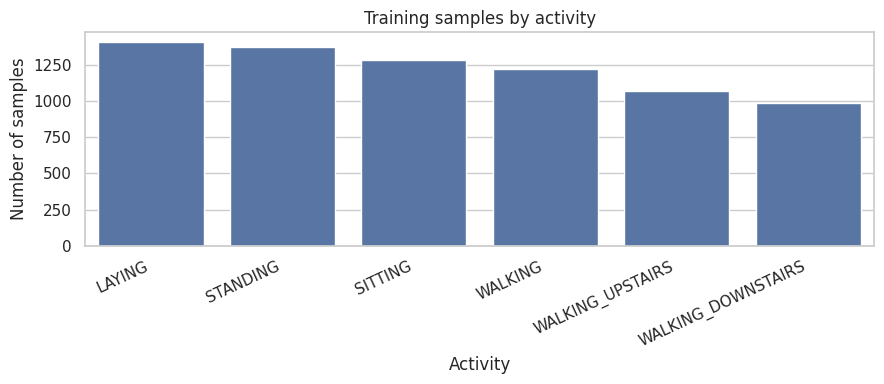

In [7]:
print("Missing values in training features:", int(X_train.isna().sum().sum()))
print("Duplicate training rows:", int(X_train.duplicated().sum()))
print("\\nTraining activity counts:")
display(y_train_names.value_counts().rename_axis("activity").to_frame("count"))

plt.figure(figsize=(9, 4))
sns.countplot(x=y_train_names, order=y_train_names.value_counts().index)
plt.title("Training samples by activity")
plt.xlabel("Activity")
plt.ylabel("Number of samples")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## 5. Train baseline models

StandardScaler is fitted inside the Logistic Regression and SVM pipelines using training data only. Random Forest uses the unscaled features. All three models are evaluated on the official test split; selecting the highest test score makes this an exploratory comparison.


In [10]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=250,
        min_samples_leaf=1,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "RBF SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", C=5, gamma="scale"))
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    trained_models[name] = model
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
display(results_df.style.format({"Accuracy": "{:.4f}"}))


Training Logistic Regression...
Training Random Forest...
Training RBF SVM...


,Model,Accuracy
0,Logistic Regression,0.9549
2,RBF SVM,0.9535
1,Random Forest,0.9284


## 6. Evaluate the highest-scoring baseline


In [11]:
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]
best_predictions = best_model.predict(X_test)

print("Best model:", best_name)
print("\\nClassification report:")
print(classification_report(
    y_test, best_predictions,
    labels=sorted(activity_names.keys()),
    target_names=[activity_names[i] for i in sorted(activity_names.keys())],
    digits=4
))


Best model: Logistic Regression
\nClassification report:
                    precision    recall  f1-score   support

           WALKING     0.9444    0.9940    0.9686       496
  WALKING_UPSTAIRS     0.9572    0.9490    0.9531       471
WALKING_DOWNSTAIRS     0.9899    0.9381    0.9633       420
           SITTING     0.9685    0.8758    0.9198       491
          STANDING     0.8885    0.9737    0.9291       532
            LAYING     0.9981    0.9907    0.9944       537

          accuracy                         0.9549      2947
         macro avg     0.9578    0.9535    0.9547      2947
      weighted avg     0.9567    0.9549    0.9548      2947



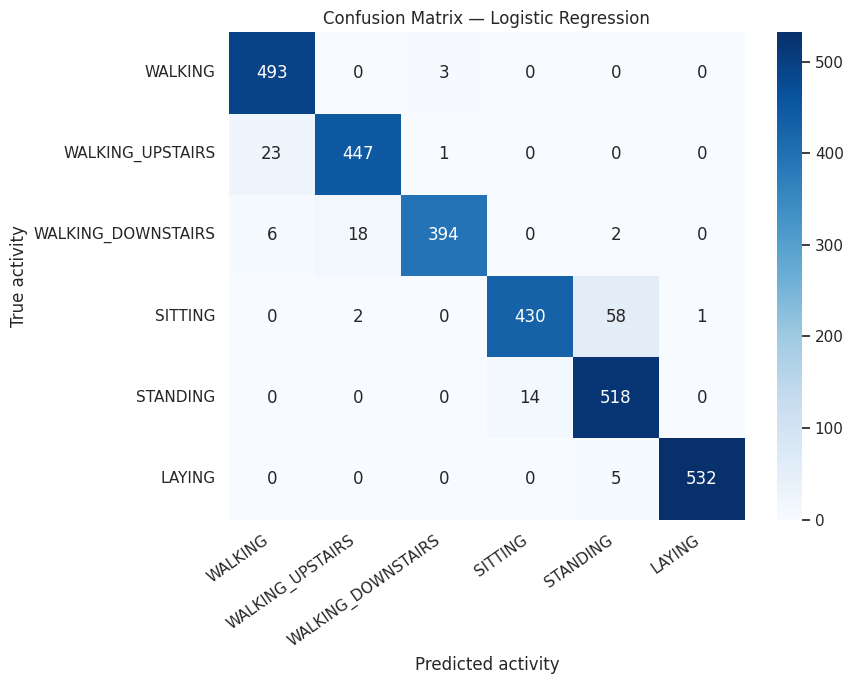

In [12]:
labels = sorted(activity_names.keys())
display_labels = [activity_names[i] for i in labels]
cm = confusion_matrix(y_test, best_predictions, labels=labels)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=display_labels, yticklabels=display_labels
)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted activity")
plt.ylabel("True activity")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 7. Feature importance (Random Forest)

Random Forest provides impurity-based feature importance. Treat this as a useful diagnostic rather than proof of causation; correlated features can split or distort importance.

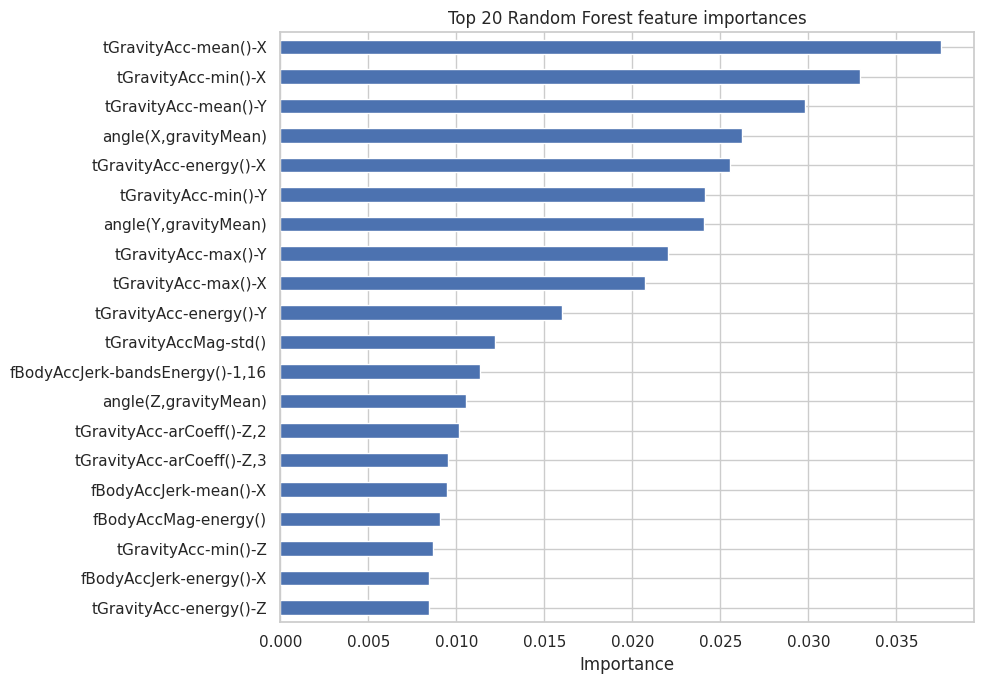

                                 importance
tGravityAcc-mean()-X               0.037535
tGravityAcc-min()-X                0.032939
tGravityAcc-mean()-Y               0.029797
angle(X,gravityMean)               0.026213
tGravityAcc-energy()-X             0.025542
tGravityAcc-min()-Y                0.024145
angle(Y,gravityMean)               0.024062
tGravityAcc-max()-Y                0.022011
tGravityAcc-max()-X                0.020712
tGravityAcc-energy()-Y             0.016008
tGravityAccMag-std()               0.012190
fBodyAccJerk-bandsEnergy()-1,16    0.011354
angle(Z,gravityMean)               0.010575
tGravityAcc-arCoeff()-Z,2          0.010128
tGravityAcc-arCoeff()-Z,3          0.009500
fBodyAccJerk-mean()-X              0.009494
fBodyAccMag-energy()               0.009082
tGravityAcc-min()-Z                0.008686
fBodyAccJerk-energy()-X            0.008469
tGravityAcc-energy()-Z             0.008462

In [13]:
rf_model = trained_models["Random Forest"]
importances = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

top_features = importances.head(20).sort_values()
plt.figure(figsize=(10, 7))
top_features.plot(kind="barh")
plt.title("Top 20 Random Forest feature importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

display(importances.head(20).rename("importance").to_frame())


## 8. Error analysis: which activities are confused?

In [14]:
# Show the most common incorrect true/predicted activity pairs
error_df = pd.DataFrame({
    "true_activity": y_test.map(activity_names).to_numpy(),
    "predicted_activity": pd.Series(best_predictions).map(activity_names).to_numpy()
})
errors = error_df[error_df["true_activity"] != error_df["predicted_activity"]]

print(f"Incorrect predictions: {len(errors)} / {len(y_test)}")
if len(errors):
    display(
        errors.groupby(["true_activity", "predicted_activity"])
        .size().sort_values(ascending=False)
        .head(10).rename("count").to_frame()
    )
else:
    print("No errors on the test set.")


Incorrect predictions: 133 / 2947


                                       count
true_activity      predicted_activity       
SITTING            STANDING               58
WALKING_UPSTAIRS   WALKING                23
WALKING_DOWNSTAIRS WALKING_UPSTAIRS       18
STANDING           SITTING                14
WALKING_DOWNSTAIRS WALKING                 6
LAYING             STANDING                5
WALKING            WALKING_DOWNSTAIRS      3
WALKING_DOWNSTAIRS STANDING                2
SITTING            WALKING_UPSTAIRS        2
                   LAYING                  1

## 9. Try a prediction on one test sample

In [15]:
sample_index = 0
sample = X_test.iloc[[sample_index]]
actual_id = int(y_test.iloc[sample_index])
predicted_id = int(best_model.predict(sample)[0])

print("Actual activity:   ", activity_names[actual_id])
print("Predicted activity:", activity_names[predicted_id])

# Optional: display probabilities for models that support predict_proba
if hasattr(best_model, "predict_proba"):
    probabilities = best_model.predict_proba(sample)[0]
    classes = best_model.classes_
    prob_df = pd.DataFrame({
        "activity": [activity_names[int(c)] for c in classes],
        "probability": probabilities
    }).sort_values("probability", ascending=False)
    display(prob_df)
else:
    print("This model does not provide predict_proba in its current configuration.")


Actual activity:    STANDING
Predicted activity: STANDING


             activity   probability
4            STANDING  9.999866e-01
3             SITTING  1.218835e-05
5              LAYING  1.210585e-06
1    WALKING_UPSTAIRS  4.046031e-09
2  WALKING_DOWNSTAIRS  1.775512e-09
0             WALKING  2.445475e-11

## 10. Conclusions and limitations

In the saved run, Logistic Regression achieved 95.49% accuracy, 0.9547 macro F1, and 0.9548 weighted F1 on 2,947 test windows. RBF SVM achieved 95.35% accuracy and Random Forest 92.84%. The small Logistic Regression/SVM gap does not establish a statistically reliable advantage.

There were 133 errors, including 58 sitting windows classified as standing and 14 standing windows classified as sitting. Random Forest assigned its largest impurity importance to tGravityAcc-mean()-X; this describes the forest, not the Logistic Regression model.

The dataset provides engineered features and a participant-disjoint train/test split. This notebook does not implement raw-signal processing, deep learning, deployment, or real-time inference. Generalization to other devices, phone placements, and populations is untested.

Future work: use participant-grouped cross-validation within training data for model selection, verify subject separation programmatically, report uncertainty and per-model macro F1, and evaluate the selected configuration on untouched data. Existing test results have already been inspected.
